# Lab 1 — Regression

Environment verification, AAPL EDA, baseline modeling, and chronological GridSearchCV are complete. Regularization and final test evaluation remain.


## 1. Problem definition and dataset source

Source: [NYSE on Kaggle](https://www.kaggle.com/datasets/dgawlik/nyse), `prices-split-adjusted.csv`. Predict AAPL next-trading-day split-adjusted close using current-day open, high, low, close, and volume available after market close. AAPL has complete observed date coverage; conclusions are limited to this stock.


## 2. Environment, seeds, and device

Kaggle environment setup and synthetic PyTorch/GridSearchCV smoke test.


In [1]:
%pip install -q skorch imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [2]:
import random
import platform
from importlib.metadata import version
from pathlib import Path

import numpy as np
import pandas as pd
import torch

SEED = 42

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

torch.backends.cudnn.deterministic = True
torch.backends.cudnn.benchmark = False

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("Python:", platform.python_version())
print("Device:", DEVICE)

if DEVICE == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

for package in [
    "torch", "scikit-learn", "skorch", "pandas",
    "numpy", "matplotlib", "seaborn", "imbalanced-learn"
]:
    print(f"{package}: {version(package)}")

Python: 3.13.15
Device: cuda
GPU: Tesla T4
torch: 2.11.0+cu128
scikit-learn: 1.6.1
skorch: 1.4.0
pandas: 2.3.3
numpy: 2.1.3
matplotlib: 3.10.0
seaborn: 0.13.2
imbalanced-learn: 0.14.2


In [3]:
from torch import nn
from skorch import NeuralNetRegressor

from sklearn.datasets import make_regression
from sklearn.model_selection import GridSearchCV, KFold
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Small synthetic regression problem for environment verification.
X_smoke, y_smoke = make_regression(
    n_samples=240,
    n_features=6,
    noise=0.1,
    random_state=SEED,
)

X_smoke = X_smoke.astype(np.float32)
y_smoke = y_smoke.astype(np.float32).reshape(-1, 1)
y_smoke /= y_smoke.std()


class SmokeMLP(nn.Module):
    def __init__(self, input_dim=6, hidden_dim=16):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.ReLU(),
            nn.Linear(hidden_dim, 1),
        )

    def forward(self, X):
        return self.network(X)


net = NeuralNetRegressor(
    module=SmokeMLP,
    criterion=nn.MSELoss,
    optimizer=torch.optim.Adam,
    lr=0.01,
    max_epochs=20,
    batch_size=32,
    train_split=False,
    iterator_train__shuffle=True,
    device=DEVICE,
    verbose=0,
)

pipeline = Pipeline([
    ("scale", StandardScaler()),
    ("net", net),
])

search = GridSearchCV(
    estimator=pipeline,
    param_grid={"net__module__hidden_dim": [8, 16]},
    scoring="neg_mean_squared_error",
    cv=KFold(n_splits=2, shuffle=True, random_state=SEED),
    n_jobs=1,
    error_score="raise",
    refit=True,
)

search.fit(X_smoke, y_smoke)

fitted_net = search.best_estimator_.named_steps["net"]
losses = np.array(fitted_net.history[:, "train_loss"])
predictions = search.predict(X_smoke[:5])

assert np.isfinite(losses).all(), "Non-finite training loss."
assert predictions.shape == (5, 1), "Unexpected prediction shape."
assert np.isfinite(predictions).all(), "Non-finite predictions."

print("PASS: PyTorch training, GridSearchCV, and prediction.")
print("Model device:", next(fitted_net.module_.parameters()).device)
print("Best parameters:", search.best_params_)
print("Best CV MSE:", -search.best_score_)
print(f"Refit training loss: {losses[0]:.4f} → {losses[-1]:.4f}")

PASS: PyTorch training, GridSearchCV, and prediction.
Model device: cuda:0
Best parameters: {'net__module__hidden_dim': 16}
Best CV MSE: 0.008058980572968721
Refit training loss: 1.0699 → 0.0026


## 3. Load and inspect NYSE data

Inspect schema, missing values, duplicates, price validity, coverage, and AAPL selection.


In [4]:
DATA_PATH = Path(
    "/kaggle/input/datasets/dgawlik/nyse/prices-split-adjusted.csv"
)

assert DATA_PATH.is_file(), f"Dataset not found: {DATA_PATH}"

prices = pd.read_csv(DATA_PATH)

required_columns = {
    "date", "symbol", "open", "close", "low", "high", "volume"
}
missing_columns = required_columns - set(prices.columns)

assert not missing_columns, f"Missing columns: {missing_columns}"

print("Shape:", prices.shape)
print("Number of stocks:", prices["symbol"].nunique())
print("Date range:", prices["date"].min(), "→", prices["date"].max())

display(prices.head())

Shape: (851264, 7)
Number of stocks: 501
Date range: 2010-01-04 → 2016-12-30


,date,symbol,open,close,low,high,volume
0,2016-01-05,WLTW,123.430000,125.839996,122.309998,126.250000,2163600.0
1,2016-01-06,WLTW,125.239998,119.980003,119.940002,125.540001,2386400.0
2,2016-01-07,WLTW,116.379997,114.949997,114.930000,119.739998,2489500.0
3,2016-01-08,WLTW,115.480003,116.620003,113.500000,117.440002,2006300.0
4,2016-01-11,WLTW,117.010002,114.970001,114.089996,117.330002,1408600.0


In [5]:
print("DATASET SIZE")
print(f"Rows: {len(prices):,}")
print(f"Columns: {prices.shape[1]}")
print(f"Stocks: {prices['symbol'].nunique():,}")

print("\nCOLUMN TYPES AND MISSING VALUES")
column_summary = pd.DataFrame({
    "dtype": prices.dtypes.astype(str),
    "missing_count": prices.isna().sum(),
    "missing_percent": prices.isna().mean().mul(100).round(3),
})
display(column_summary)

parsed_dates = pd.to_datetime(
    prices["date"],
    format="%Y-%m-%d",
    errors="coerce",
)

print("\nDATES")
print("Invalid or missing dates:", parsed_dates.isna().sum())
print("Earliest date:", parsed_dates.min())
print("Latest date:", parsed_dates.max())

print("\nDUPLICATES")
print("Fully duplicated rows:", prices.duplicated().sum())
print(
    "Extra rows with a repeated (symbol, date) key:",
    prices.duplicated(subset=["symbol", "date"]).sum(),
)

date_order = (
    prices.assign(parsed_date=parsed_dates)
    .groupby("symbol")["parsed_date"]
    .apply(lambda dates: dates.is_monotonic_increasing)
)

print("\nROW ORDER")
print("Entire file sorted by date:", parsed_dates.is_monotonic_increasing)
print("Stocks with dates in ascending order:", int(date_order.sum()))
print("Stocks requiring date sorting:", int((~date_order).sum()))

DATASET SIZE
Rows: 851,264
Columns: 7
Stocks: 501

COLUMN TYPES AND MISSING VALUES


,dtype,missing_count,missing_percent
date,object,0,0.0
symbol,object,0,0.0
open,float64,0,0.0
close,float64,0,0.0
low,float64,0,0.0
high,float64,0,0.0
volume,float64,0,0.0



DATES
Invalid or missing dates: 0
Earliest date: 2010-01-04 00:00:00
Latest date: 2016-12-30 00:00:00

DUPLICATES
Fully duplicated rows: 0
Extra rows with a repeated (symbol, date) key: 0

ROW ORDER
Entire file sorted by date: False
Stocks with dates in ascending order: 501
Stocks requiring date sorting: 0


In [6]:
stock_data = prices.copy()
stock_data["date"] = pd.to_datetime(stock_data["date"], format="%Y-%m-%d")
stock_data = stock_data.sort_values(["symbol", "date"]).reset_index(drop=True)

coverage = (
    stock_data.groupby("symbol")
    .agg(
        rows=("date", "size"),
        first_date=("date", "min"),
        last_date=("date", "max"),
    )
    .sort_values(["rows", "symbol"], ascending=[False, True])
)

print("STOCK COVERAGE")
display(coverage.head(15))

print("ROWS PER STOCK")
display(coverage["rows"].describe().to_frame("rows"))

price_columns = ["open", "close", "low", "high"]
numeric_columns = price_columns + ["volume"]

checks = pd.Series({
    "Rows with non-finite numeric values": (
        ~np.isfinite(stock_data[numeric_columns]).all(axis=1)
    ).sum(),
    "Rows with non-positive prices": (
        stock_data[price_columns] <= 0
    ).any(axis=1).sum(),
    "Rows with negative volume": (stock_data["volume"] < 0).sum(),
    "Rows with zero volume": (stock_data["volume"] == 0).sum(),
    "Rows with low above high": (
        stock_data["low"] > stock_data["high"]
    ).sum(),
    "Rows with open outside low/high": (
        (stock_data["open"] < stock_data["low"])
        | (stock_data["open"] > stock_data["high"])
    ).sum(),
    "Rows with close outside low/high": (
        (stock_data["close"] < stock_data["low"])
        | (stock_data["close"] > stock_data["high"])
    ).sum(),
})

print("DATA VALIDITY CHECKS")
display(checks.to_frame("row_count"))

STOCK COVERAGE


,rows,first_date,last_date
symbol,,,
A,1762,2010-01-04,2016-12-30
AAL,1762,2010-01-04,2016-12-30
AAP,1762,2010-01-04,2016-12-30
AAPL,1762,2010-01-04,2016-12-30
ABC,1762,2010-01-04,2016-12-30
ABT,1762,2010-01-04,2016-12-30
ACN,1762,2010-01-04,2016-12-30
ADBE,1762,2010-01-04,2016-12-30
ADI,1762,2010-01-04,2016-12-30


ROWS PER STOCK


,rows
count,501.000000
mean,1699.129741
std,253.731238
min,126.000000
25%,1762.000000
50%,1762.000000
75%,1762.000000
max,1762.000000


DATA VALIDITY CHECKS


,row_count
Rows with non-finite numeric values,0
Rows with non-positive prices,0
Rows with negative volume,0
Rows with zero volume,21
Rows with low above high,0
Rows with open outside low/high,0
Rows with close outside low/high,0


In [7]:
zero_volume_rows = stock_data.loc[
    stock_data["volume"].eq(0),
    ["symbol", "date", "open", "close", "low", "high", "volume"],
]

print("ZERO-VOLUME RECORDS")
display(zero_volume_rows)

SYMBOL = "AAPL"

stock = (
    stock_data.loc[stock_data["symbol"].eq(SYMBOL)]
    .sort_values("date")
    .reset_index(drop=True)
    .copy()
)

assert not stock.empty, f"No records found for {SYMBOL}"
assert stock["date"].is_unique
assert stock["date"].is_monotonic_increasing

observed_market_dates = pd.DatetimeIndex(stock_data["date"].unique()).sort_values()
missing_dates = observed_market_dates.difference(
    pd.DatetimeIndex(stock["date"])
)

print(f"\nCANDIDATE STOCK: {SYMBOL}")
print("Rows:", len(stock))
print("First date:", stock["date"].min().date())
print("Last date:", stock["date"].max().date())
print("Zero-volume rows:", stock["volume"].eq(0).sum())
print("Dates present elsewhere in the dataset but absent for AAPL:",
      len(missing_dates))

if len(missing_dates):
    print(missing_dates.strftime("%Y-%m-%d").tolist())

print("\nFIRST RECORDS")
display(stock.head())

ZERO-VOLUME RECORDS


,symbol,date,open,close,low,high,volume
133701,CB,2016-01-15,111.019997,111.019997,111.019997,111.019997,0.0
152069,CHTR,2010-01-06,35.000000,35.000000,35.000000,35.000000,0.0
152096,CHTR,2010-02-16,29.740000,29.740000,29.740000,29.740000,0.0
152097,CHTR,2010-02-17,29.740000,29.740000,29.740000,29.740000,0.0
152099,CHTR,2010-02-19,29.700001,29.700001,29.700001,29.700001,0.0
152101,CHTR,2010-02-23,29.700001,29.700001,29.700001,29.700001,0.0
152102,CHTR,2010-02-24,29.700001,29.700001,29.700001,29.700001,0.0
152132,CHTR,2010-04-08,34.549999,34.549999,34.549999,34.549999,0.0
152135,CHTR,2010-04-13,35.000000,35.000000,35.000000,35.000000,0.0
152140,CHTR,2010-04-20,36.009998,36.009998,36.009998,36.009998,0.0



CANDIDATE STOCK: AAPL
Rows: 1762
First date: 2010-01-04
Last date: 2016-12-30
Zero-volume rows: 0
Dates present elsewhere in the dataset but absent for AAPL: 0

FIRST RECORDS


,date,symbol,open,close,low,high,volume
0,2010-01-04,AAPL,30.490000,30.572857,30.340000,30.642857,123432400.0
1,2010-01-05,AAPL,30.657143,30.625713,30.464285,30.798571,150476200.0
2,2010-01-06,AAPL,30.625713,30.138571,30.107143,30.747143,138040000.0
3,2010-01-07,AAPL,30.250000,30.082857,29.864286,30.285715,119282800.0
4,2010-01-08,AAPL,30.042856,30.282858,29.865715,30.285715,111902700.0


## 4. Chronological splits and exploratory analysis

Define next-day targets and chronological partitions; explore training data only and verify partition boundaries.


In [8]:
FEATURES = ["open", "high", "low", "close", "volume"]
TARGET = "next_close"

supervised = stock.copy()
supervised[TARGET] = supervised["close"].shift(-1)
supervised["target_date"] = supervised["date"].shift(-1)
supervised = supervised.dropna(subset=[TARGET, "target_date"]).copy()

validation_start = pd.Timestamp("2015-01-01")
test_start = pd.Timestamp("2016-01-01")

train = supervised.loc[
    supervised["target_date"] < validation_start
].copy()

validation = supervised.loc[
    (supervised["date"] >= validation_start)
    & (supervised["target_date"] < test_start)
].copy()

test = supervised.loc[
    supervised["date"] >= test_start
].copy()

assert all(len(part) > 0 for part in [train, validation, test])
assert train["target_date"].max() < validation["date"].min()
assert validation["target_date"].max() < test["date"].min()
assert (supervised["target_date"] > supervised["date"]).all()

split_summary = pd.DataFrame([
    {
        "split": name,
        "samples": len(part),
        "first_input_date": part["date"].min(),
        "last_input_date": part["date"].max(),
        "first_target_date": part["target_date"].min(),
        "last_target_date": part["target_date"].max(),
    }
    for name, part in [
        ("train", train),
        ("validation", validation),
        ("test", test),
    ]
]).set_index("split")

display(split_summary)

excluded = len(supervised) - len(train) - len(validation) - len(test)
print("Examples excluded at split boundaries:", excluded)
print("Input features:", FEATURES)
print("Target:", TARGET)

,samples,first_input_date,last_input_date,first_target_date,last_target_date
split,,,,,
train,1257,2010-01-04,2014-12-30,2010-01-05,2014-12-31
validation,251,2015-01-02,2015-12-30,2015-01-05,2015-12-31
test,251,2016-01-04,2016-12-29,2016-01-05,2016-12-30


Examples excluded at split boundaries: 2
Input features: ['open', 'high', 'low', 'close', 'volume']
Target: next_close


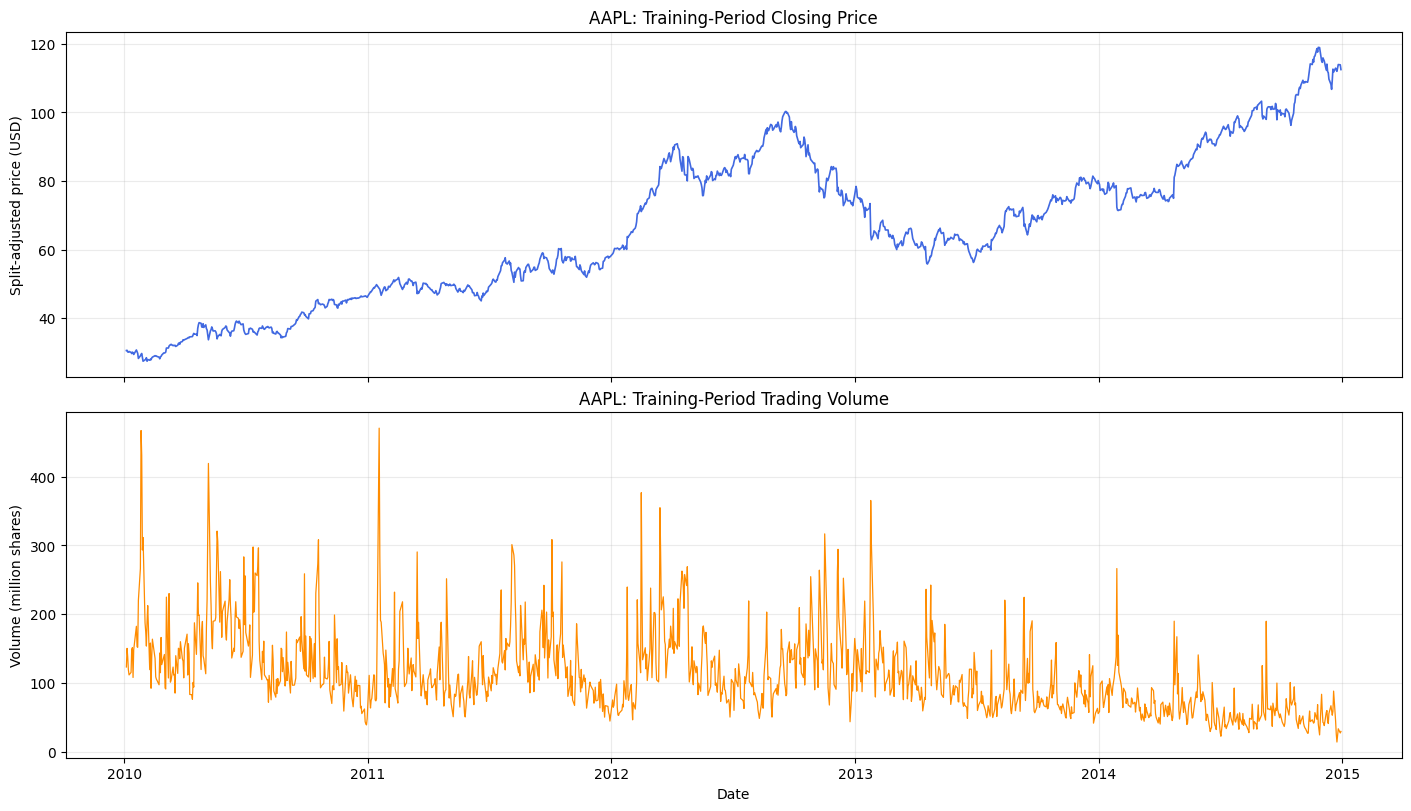

In [9]:
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
from pathlib import Path

PLOT_DIR = Path("/kaggle/working/plots")
PLOT_DIR.mkdir(parents=True, exist_ok=True)

fig, axes = plt.subplots(
    2, 1, figsize=(14, 8), sharex=True, constrained_layout=True
)

axes[0].plot(
    train["date"],
    train["close"],
    color="royalblue",
    linewidth=1.2,
)
axes[0].set_title(f"{SYMBOL}: Training-Period Closing Price")
axes[0].set_ylabel("Split-adjusted price (USD)")
axes[0].grid(alpha=0.25)

axes[1].plot(
    train["date"],
    train["volume"] / 1_000_000,
    color="darkorange",
    linewidth=0.9,
)
axes[1].set_title(f"{SYMBOL}: Training-Period Trading Volume")
axes[1].set_ylabel("Volume (million shares)")
axes[1].set_xlabel("Date")
axes[1].grid(alpha=0.25)

axes[1].xaxis.set_major_locator(mdates.YearLocator())
axes[1].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

fig.savefig(
    PLOT_DIR / "aapl_training_price_volume.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

,count,mean,std,min,1%,25%,50%,75%,99%,max
open,1257.0,6.620000e+01,21.62,27.48,28.66,48.88,6.494000e+01,8.207000e+01,1.141700e+02,1.192700e+02
high,1257.0,6.680000e+01,21.80,28.00,28.91,49.24,6.538000e+01,8.247000e+01,1.157100e+02,1.197500e+02
low,1257.0,6.553000e+01,21.45,27.18,28.15,48.36,6.418000e+01,8.129000e+01,1.129900e+02,1.180500e+02
close,1257.0,6.618000e+01,21.62,27.44,28.56,48.81,6.471000e+01,8.174000e+01,1.143800e+02,1.190000e+02
volume,1257.0,1.139543e+08,59640235.51,14479600.00,32842360.00,71766800.00,1.010128e+08,1.414658e+08,3.069510e+08,4.702495e+08


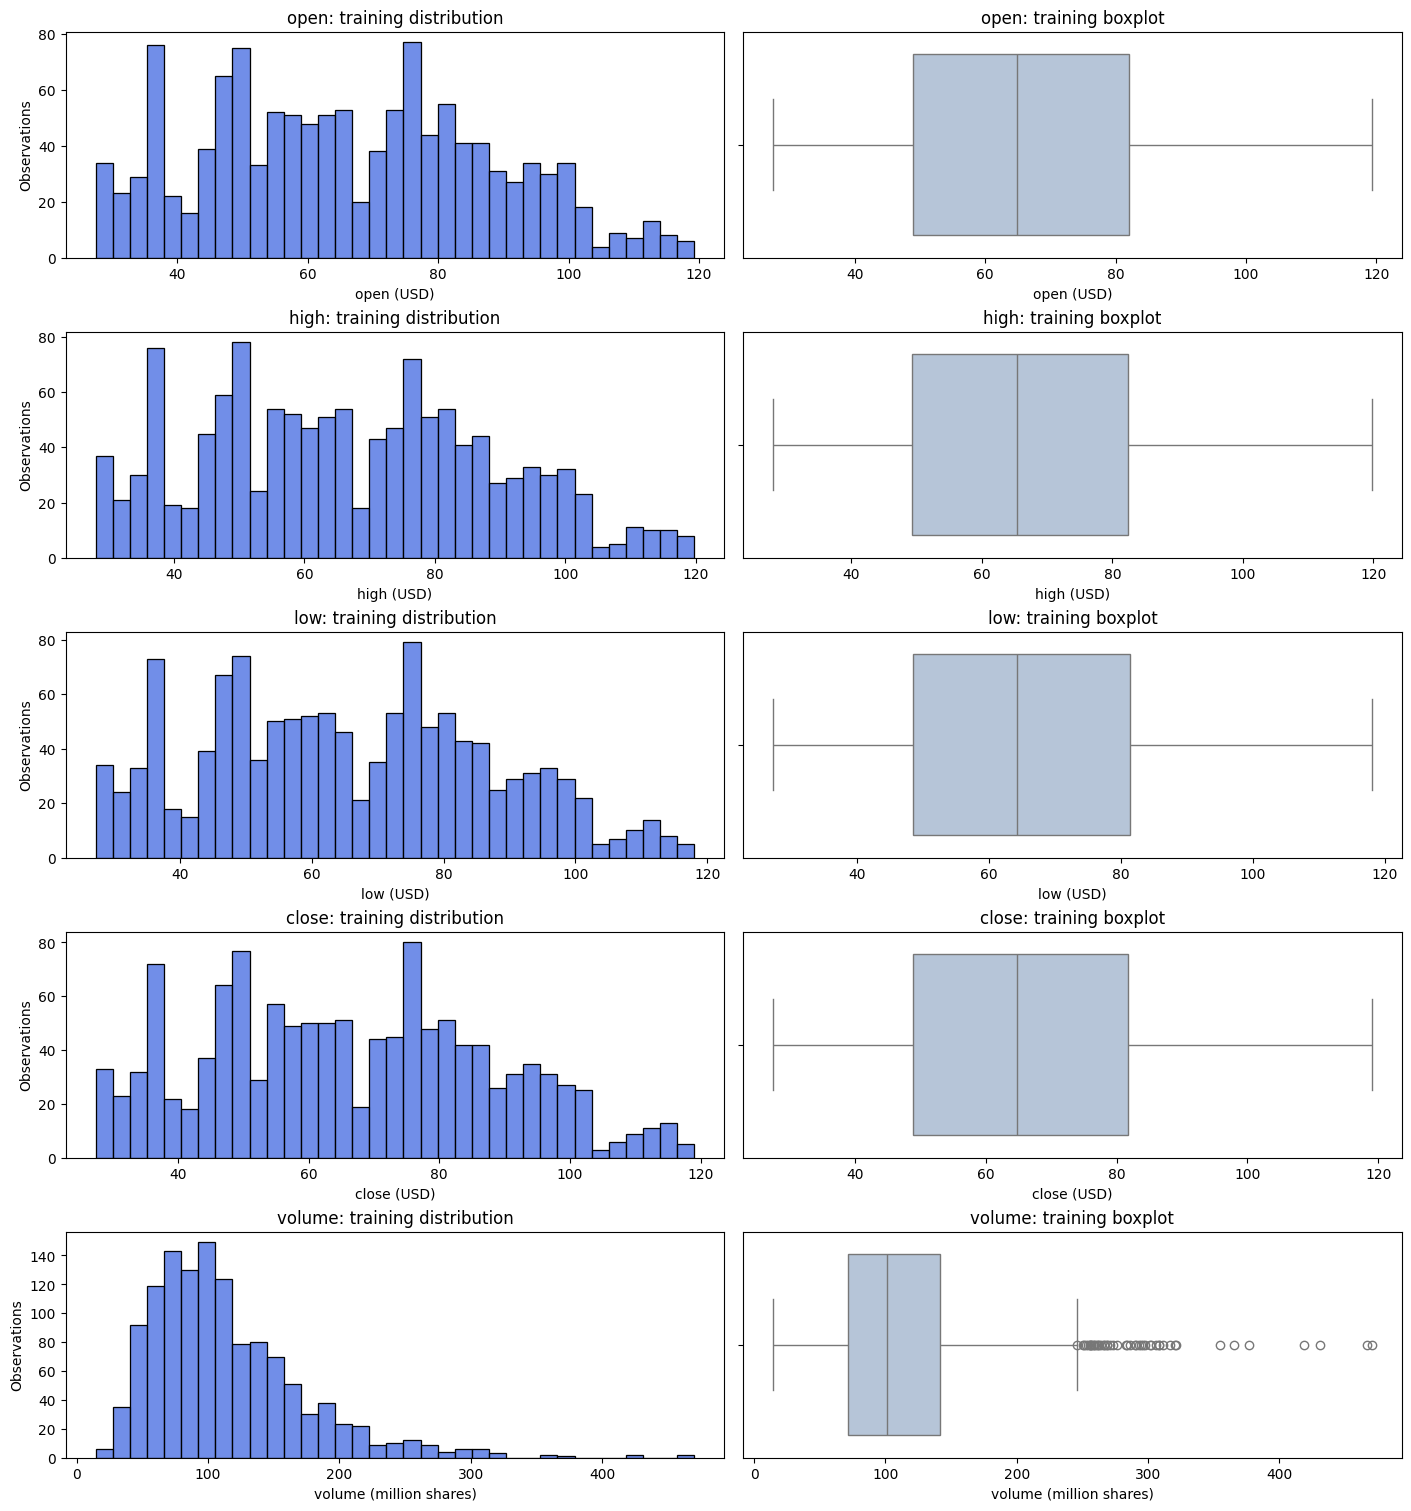

In [10]:
import seaborn as sns

display(
    train[FEATURES]
    .describe(percentiles=[0.01, 0.25, 0.5, 0.75, 0.99])
    .T.round(2)
)

fig, axes = plt.subplots(
    len(FEATURES),
    2,
    figsize=(14, 15),
    constrained_layout=True,
)

for row, feature in enumerate(FEATURES):
    values = train[feature]
    unit = "USD"

    if feature == "volume":
        values = values / 1_000_000
        unit = "million shares"

    sns.histplot(
        x=values,
        bins=35,
        ax=axes[row, 0],
        color="royalblue",
    )
    axes[row, 0].set_title(f"{feature}: training distribution")
    axes[row, 0].set_xlabel(f"{feature} ({unit})")
    axes[row, 0].set_ylabel("Observations")

    sns.boxplot(
        x=values,
        ax=axes[row, 1],
        color="lightsteelblue",
        whis=1.5,
    )
    axes[row, 1].set_title(f"{feature}: training boxplot")
    axes[row, 1].set_xlabel(f"{feature} ({unit})")

fig.savefig(
    PLOT_DIR / "aapl_training_distributions_boxplots.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

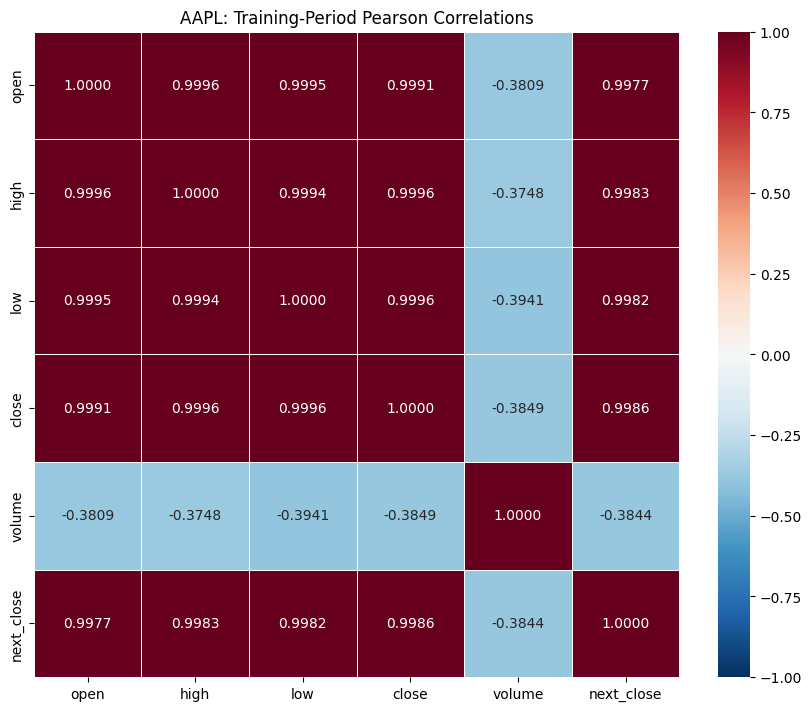

FEATURE CORRELATIONS WITH NEXT-DAY CLOSE


,pearson_correlation
close,0.998624
high,0.998253
low,0.998212
open,0.997717
volume,-0.384437


In [11]:
correlation_columns = FEATURES + [TARGET]
correlations = train[correlation_columns].corr(method="pearson")

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)

sns.heatmap(
    correlations,
    annot=True,
    fmt=".4f",
    cmap="RdBu_r",
    vmin=-1,
    vmax=1,
    center=0,
    square=True,
    linewidths=0.5,
    ax=ax,
)

ax.set_title(f"{SYMBOL}: Training-Period Pearson Correlations")

fig.savefig(
    PLOT_DIR / "aapl_training_correlations.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

print("FEATURE CORRELATIONS WITH NEXT-DAY CLOSE")
display(
    correlations.loc[FEATURES, TARGET]
    .sort_values(ascending=False)
    .to_frame("pearson_correlation")
    .round(6)
)

TRAINING NEXT-DAY CHANGE (%)


,next_day_change_pct
count,1257.000
mean,0.116
std,1.679
min,-12.356
1%,-4.238
5%,-2.499
50%,0.100
95%,2.645
99%,4.780
max,8.874


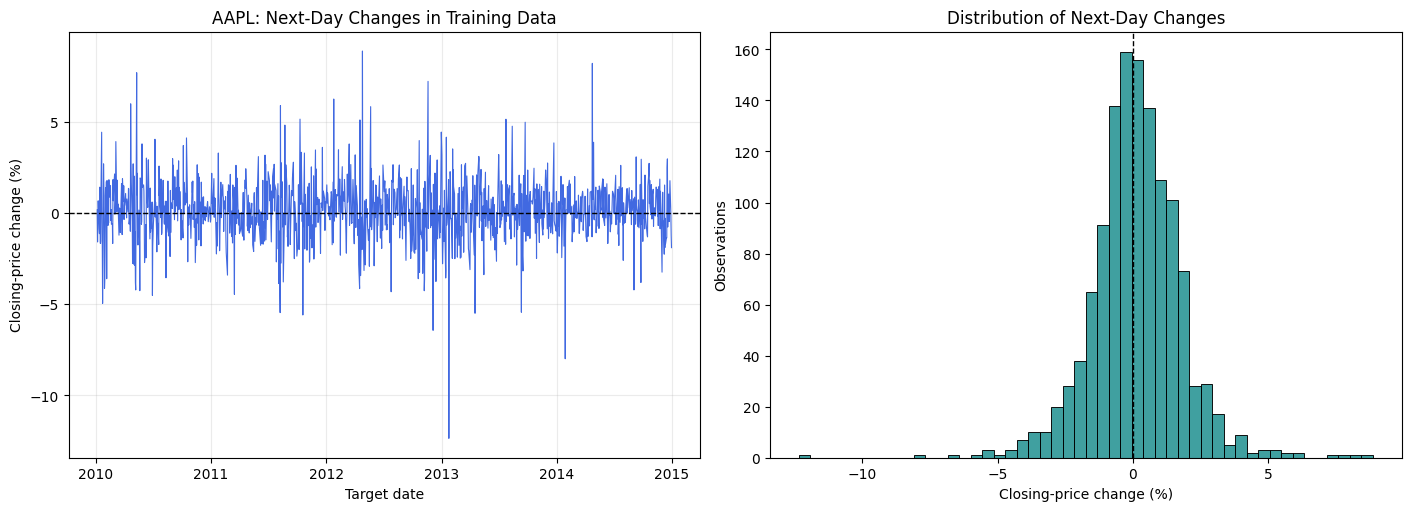

In [12]:
next_day_change_pct = (
    (train[TARGET] / train["close"]) - 1
) * 100

print("TRAINING NEXT-DAY CHANGE (%)")
display(
    next_day_change_pct.describe(
        percentiles=[0.01, 0.05, 0.5, 0.95, 0.99]
    ).to_frame("next_day_change_pct").round(3)
)

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5), constrained_layout=True
)

axes[0].plot(
    train["target_date"],
    next_day_change_pct,
    color="royalblue",
    linewidth=0.8,
)
axes[0].axhline(0, color="black", linestyle="--", linewidth=1)
axes[0].set_title(f"{SYMBOL}: Next-Day Changes in Training Data")
axes[0].set_xlabel("Target date")
axes[0].set_ylabel("Closing-price change (%)")
axes[0].grid(alpha=0.25)
axes[0].xaxis.set_major_locator(mdates.YearLocator())
axes[0].xaxis.set_major_formatter(mdates.DateFormatter("%Y"))

sns.histplot(
    x=next_day_change_pct,
    bins=50,
    color="teal",
    ax=axes[1],
)
axes[1].axvline(0, color="black", linestyle="--", linewidth=1)
axes[1].set_title("Distribution of Next-Day Changes")
axes[1].set_xlabel("Closing-price change (%)")
axes[1].set_ylabel("Observations")

fig.savefig(
    PLOT_DIR / "aapl_training_next_day_changes.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

### EDA conclusions

- The NYSE dataset contains 851,264 rows, seven columns, and 501 stocks.
  No missing values, invalid dates, duplicate stock/date records, or
  inconsistent OHLC price relationships were found.
- There are 21 zero-volume records across other stocks. AAPL has none
  and covers all 1,762 trading dates observed in the dataset.
  
- This experiment uses AAPL only. Its conclusions therefore cannot
  automatically be generalized to other stocks.

### Prediction task and chronological splits

Predict the next trading day's split-adjusted closing price after the
current day's market close.

Inputs: current-day open, high, low, close, and volume.
Target: next_close. The date, symbol, target_date, and next_close are
excluded from model inputs.

| Partition | Period | Samples |
|---|---|---:|
| Training | 2010–2014 | 1,257 |
| Validation | 2015 | 251 |
| Test | 2016 | 251 |

The final observation has no next-day target and is excluded.
Two additional examples are excluded because their targets cross
partition boundaries. No random shuffling is used for these splits.
Distribution and relationship analysis uses training data only.

### Main findings

- Closing prices show an overall upward trend, interrupted by a
  substantial decline from late 2012 into 2013.
- Open, high, low, and close have very similar distributions and
  correlations above 0.999 with one another.
- Volume is right-skewed and has a much larger numerical scale than
  prices. High-volume observations are retained.
- Today's close correlates strongly with next-day close (0.998624).
  This does not demonstrate useful forecasting performance:
  the model must be compared with a persistence baseline.
- Next-day percentage changes average approximately 0.116%, with a
  standard deviation of 1.679 percentage points. The middle 90%
  range from approximately −2.499% to +2.645%.
- Extreme next-day changes range from −12.356% to +8.874%.
  These observations are retained rather than automatically removed.

### Modeling decisions

- Begin with the five specified input features.
- Fit preprocessing only on training data, including within CV folds.
- Compare the MLP with the baseline: tomorrow's predicted close
  equals today's close.
- Use validation results for model selection and keep the test set
  reserved for final reporting.
- Evaluate regression with MAE, RMSE, and R².

In [13]:
partitions = {
    "train": train,
    "validation": validation,
    "test": test,
}

for name, part in partitions.items():
    assert part["date"].is_monotonic_increasing, name
    assert part["date"].is_unique, name
    assert (part["target_date"] > part["date"]).all(), name
    assert part[FEATURES + [TARGET]].notna().all().all(), name

assert set(train.index).isdisjoint(validation.index)
assert set(train.index).isdisjoint(test.index)
assert set(validation.index).isdisjoint(test.index)

assert train["target_date"].max() < validation["date"].min()
assert validation["target_date"].max() < test["date"].min()

assert TARGET not in FEATURES
assert "target_date" not in FEATURES

expected = stock.set_index("date")["close"].shift(-1)
for name, part in partitions.items():
    np.testing.assert_allclose(
        part[TARGET].to_numpy(),
        expected.loc[part["date"]].to_numpy(),
        rtol=0,
        atol=0,
        err_msg=f"Incorrect next-day target in {name}",
    )

included_indices = train.index.union(validation.index).union(test.index)
excluded_boundaries = supervised.loc[
    ~supervised.index.isin(included_indices),
    ["date", "target_date", "close", TARGET],
]

RESULTS_DIR = Path("/kaggle/working/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

split_summary.to_csv(
    RESULTS_DIR / "aapl_split_summary.csv",
    date_format="%Y-%m-%d",
)

excluded_boundaries.to_csv(
    RESULTS_DIR / "aapl_excluded_boundary_rows.csv",
    index=False,
    date_format="%Y-%m-%d",
)

display(split_summary)
print("EXCLUDED BOUNDARY EXAMPLES")
display(excluded_boundaries)

print("PASS: disjoint partitions, chronological boundaries, and target alignment.")
print("Split records saved to:", RESULTS_DIR)

,samples,first_input_date,last_input_date,first_target_date,last_target_date
split,,,,,
train,1257,2010-01-04,2014-12-30,2010-01-05,2014-12-31
validation,251,2015-01-02,2015-12-30,2015-01-05,2015-12-31
test,251,2016-01-04,2016-12-29,2016-01-05,2016-12-30


EXCLUDED BOUNDARY EXAMPLES


,date,target_date,close,next_close
1257,2014-12-31,2015-01-02,110.379997,109.330002
1509,2015-12-31,2016-01-04,105.260002,105.349998


PASS: disjoint partitions, chronological boundaries, and target alignment.
Split records saved to: /kaggle/working/results


## 5. Training-only preprocessing and persistence baseline

TODO: implement and document this section.


In [15]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
        "R2": r2_score(y_true, y_pred),
    }

persistence_results = pd.DataFrame({
    name: regression_metrics(
        part[TARGET].to_numpy(),
        part["close"].to_numpy(),
    )
    for name, part in [
        ("train", train),
        ("validation", validation),
    ]
}).T

persistence_results.index.name = "split"

print("PERSISTENCE BASELINE")
print("Prediction: next trading-day close = current-day close")
print("MAE and RMSE are in USD.")
display(persistence_results.round(6))

RESULTS_DIR = Path("/kaggle/working/results")
RESULTS_DIR.mkdir(parents=True, exist_ok=True)

persistence_results.to_csv(
    RESULTS_DIR / "aapl_persistence_train_validation.csv"
)

PERSISTENCE BASELINE
Prediction: next trading-day close = current-day close
MAE and RMSE are in USD.


,MAE,RMSE,R2
split,,,
train,0.790716,1.135872,0.997240
validation,1.497729,1.966823,0.933962


In [17]:
from sklearn.preprocessing import StandardScaler

X_train_raw = train[FEATURES].to_numpy(dtype=np.float64)
X_val_raw = validation[FEATURES].to_numpy(dtype=np.float64)

y_train_raw = train[[TARGET]].to_numpy(dtype=np.float64)
y_val_raw = validation[[TARGET]].to_numpy(dtype=np.float64)

x_scaler = StandardScaler()
y_scaler = StandardScaler()

X_train = x_scaler.fit_transform(X_train_raw).astype(np.float32)
X_val = x_scaler.transform(X_val_raw).astype(np.float32)

y_train = y_scaler.fit_transform(y_train_raw).astype(np.float32)
y_val = y_scaler.transform(y_val_raw).astype(np.float32)

assert int(x_scaler.n_samples_seen_) == len(train)
assert int(y_scaler.n_samples_seen_) == len(train)

for array in [X_train, X_val, y_train, y_val]:
    assert np.isfinite(array).all()

np.testing.assert_allclose(X_train.mean(axis=0), 0, atol=1e-6)
np.testing.assert_allclose(X_train.std(axis=0), 1, atol=1e-6)

X_train_tensor = torch.from_numpy(X_train)
X_val_tensor = torch.from_numpy(X_val)
y_train_tensor = torch.from_numpy(y_train)
y_val_tensor = torch.from_numpy(y_val)

scaling_summary = pd.DataFrame({
    "feature": FEATURES,
    "training_mean": x_scaler.mean_,
    "training_scale": x_scaler.scale_,
    "scaled_train_mean": X_train.mean(axis=0),
    "scaled_train_std": X_train.std(axis=0),
    "scaled_validation_mean": X_val.mean(axis=0),
})

display(scaling_summary.round(4))

print("Training tensors:", X_train_tensor.shape, y_train_tensor.shape)
print("Validation tensors:", X_val_tensor.shape, y_val_tensor.shape)
print("Target training mean:", round(y_scaler.mean_[0], 4))
print("Target training scale:", round(y_scaler.scale_[0], 4))
print("PASS: scalers fitted on training data only; all arrays are finite.")

,feature,training_mean,training_scale,scaled_train_mean,scaled_train_std,scaled_validation_mean
0,open,6.620410e+01,2.161220e+01,0.0,1.0,2.4997
1,high,6.680430e+01,2.178660e+01,0.0,1.0,2.5014
2,low,6.552910e+01,2.144150e+01,-0.0,1.0,2.4900
3,close,6.617890e+01,2.160980e+01,0.0,1.0,2.4952
4,volume,1.139543e+08,5.961651e+07,-0.0,1.0,-1.0412


Training tensors: torch.Size([1257, 5]) torch.Size([1257, 1])
Validation tensors: torch.Size([251, 5]) torch.Size([251, 1])
Target training mean: 66.2424
Target training scale: 21.6223
PASS: scalers fitted on training data only; all arrays are finite.


## 6. Baseline PyTorch MLP

TODO: implement and document this section.


In [19]:
from torch import nn
from torch.utils.data import DataLoader, TensorDataset

random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)


class RegressionMLP(nn.Module):
    def __init__(self, input_dim=5):
        super().__init__()
        self.network = nn.Sequential(
            nn.Linear(input_dim, 32),
            nn.ReLU(),
            nn.Linear(32, 16),
            nn.ReLU(),
            nn.Linear(16, 1),
        )

    def forward(self, x):
        return self.network(x)


BATCH_SIZE = 32
LEARNING_RATE = 0.001
EPOCHS = 100

loader_generator = torch.Generator().manual_seed(SEED)

train_loader = DataLoader(
    TensorDataset(X_train_tensor, y_train_tensor),
    batch_size=BATCH_SIZE,
    shuffle=True,
    generator=loader_generator,
    num_workers=0,
)

model = RegressionMLP(input_dim=len(FEATURES)).to(DEVICE)
criterion = nn.MSELoss()
optimizer = torch.optim.Adam(
    model.parameters(),
    lr=LEARNING_RATE,
)

with torch.no_grad():
    sample_output = model(X_train_tensor[:8].to(DEVICE))

assert sample_output.shape == (8, 1)
assert torch.isfinite(sample_output).all()

print(model)
print("Trainable parameters:", sum(
    p.numel() for p in model.parameters() if p.requires_grad
))
print("Device:", next(model.parameters()).device)
print("Batches per epoch:", len(train_loader))
print("Sample output shape:", sample_output.shape)
print("PASS: model forward pass.")

RegressionMLP(
  (network): Sequential(
    (0): Linear(in_features=5, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=16, bias=True)
    (3): ReLU()
    (4): Linear(in_features=16, out_features=1, bias=True)
  )
)
Trainable parameters: 737
Device: cuda:0
Batches per epoch: 40
Sample output shape: torch.Size([8, 1])
PASS: model forward pass.


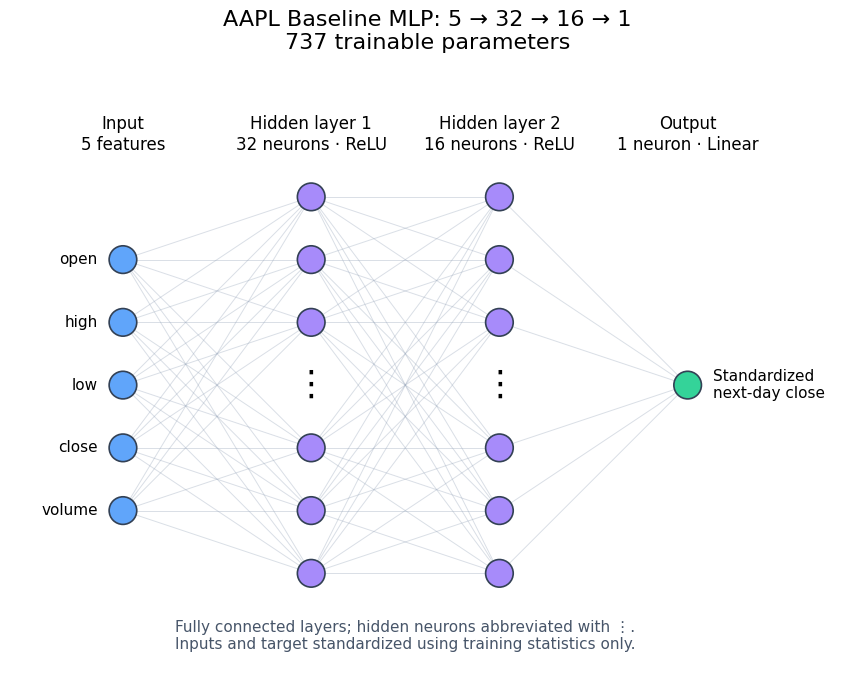

In [23]:
from matplotlib.patches import Circle
from matplotlib.lines import Line2D

linear_layers = [
    layer for layer in model.network
    if isinstance(layer, nn.Linear)
]

layer_sizes = [
    linear_layers[0].in_features,
    *[layer.out_features for layer in linear_layers],
]

layer_titles = [
    "Input\n5 features",
    "Hidden layer 1\n32 neurons · ReLU",
    "Hidden layer 2\n16 neurons · ReLU",
    "Output\n1 neuron · Linear",
]

colors = ["#60a5fa", "#a78bfa", "#a78bfa", "#34d399"]
x_positions = [0, 3, 6, 9]

fig, ax = plt.subplots(figsize=(14, 7))
positions = []

for x, size in zip(x_positions, layer_sizes):
    if size > 8:
        y_positions = [3, 2, 1, -1, -2, -3]
        ax.text(x, 0, "⋮", ha="center", va="center", fontsize=25)
    else:
        y_positions = np.linspace(
            (size - 1) / 2,
            -(size - 1) / 2,
            size,
        )

    positions.append([(x, float(y)) for y in y_positions])

for left_layer, right_layer in zip(positions[:-1], positions[1:]):
    for x1, y1 in left_layer:
        for x2, y2 in right_layer:
            ax.add_line(Line2D(
                [x1, x2],
                [y1, y2],
                color="#94a3b8",
                linewidth=0.7,
                alpha=0.35,
                zorder=1,
            ))

for nodes, color, title, x in zip(
    positions, colors, layer_titles, x_positions
):
    for node in nodes:
        ax.add_patch(Circle(
            node,
            radius=0.22,
            facecolor=color,
            edgecolor="#334155",
            linewidth=1.2,
            zorder=2,
        ))

    ax.text(x, 4, title, ha="center", va="center", fontsize=12)

for (_, y), feature in zip(positions[0], FEATURES):
    ax.text(-0.4, y, feature, ha="right", va="center", fontsize=11)

ax.text(
    9.4, 0,
    "Standardized\nnext-day close",
    ha="left",
    va="center",
    fontsize=11,
)

parameter_count = sum(
    p.numel() for p in model.parameters() if p.requires_grad
)

ax.set_title(
    f"AAPL Baseline MLP: {' → '.join(map(str, layer_sizes))}\n"
    f"{parameter_count:,} trainable parameters",
    fontsize=16,
    pad=25,
)

ax.text(
    4.5, -4,
    "Fully connected layers; hidden neurons abbreviated with ⋮.\n"
    "Inputs and target standardized using training statistics only.",
    ha="center",
    va="center",
    fontsize=11,
    color="#475569",
)

ax.set_xlim(-1.8, 11.5)
ax.set_ylim(-4.7, 4.8)
ax.set_aspect("equal")
ax.axis("off")

fig.tight_layout()
fig.savefig(
    PLOT_DIR / "aapl_baseline_architecture.png",
    dpi=180,
    bbox_inches="tight",
)
plt.show()

In [20]:
X_train_device = X_train_tensor.to(DEVICE)
X_val_device = X_val_tensor.to(DEVICE)
y_train_device = y_train_tensor.to(DEVICE)
y_val_device = y_val_tensor.to(DEVICE)

history_rows = []

for epoch in range(1, EPOCHS + 1):
    model.train()

    for X_batch, y_batch in train_loader:
        X_batch = X_batch.to(DEVICE)
        y_batch = y_batch.to(DEVICE)

        optimizer.zero_grad(set_to_none=True)
        predictions = model(X_batch)
        loss = criterion(predictions, y_batch)

        if not torch.isfinite(loss):
            raise RuntimeError(f"Non-finite loss at epoch {epoch}")

        loss.backward()
        optimizer.step()

    model.eval()

    with torch.no_grad():
        train_predictions_scaled = model(X_train_device)
        val_predictions_scaled = model(X_val_device)

        train_loss = criterion(
            train_predictions_scaled, y_train_device
        ).item()
        val_loss = criterion(
            val_predictions_scaled, y_val_device
        ).item()

    train_predictions = y_scaler.inverse_transform(
        train_predictions_scaled.cpu().numpy()
    )
    val_predictions = y_scaler.inverse_transform(
        val_predictions_scaled.cpu().numpy()
    )

    train_metrics = regression_metrics(
        y_train_raw.ravel(), train_predictions.ravel()
    )
    val_metrics = regression_metrics(
        y_val_raw.ravel(), val_predictions.ravel()
    )

    history_rows.append({
        "epoch": epoch,
        "train_loss": train_loss,
        "validation_loss": val_loss,
        **{f"train_{key}": value for key, value in train_metrics.items()},
        **{f"validation_{key}": value for key, value in val_metrics.items()},
    })

    if epoch == 1 or epoch % 10 == 0:
        print(
            f"Epoch {epoch:3d}/{EPOCHS} | "
            f"MSE (scaled): {train_loss:.5f} / {val_loss:.5f} | "
            f"R²: {train_metrics['R2']:.4f} / {val_metrics['R2']:.4f} | "
            f"Validation RMSE: ${val_metrics['RMSE']:.4f}"
        )

history = pd.DataFrame(history_rows)

assert len(history) == EPOCHS
assert np.isfinite(history.to_numpy()).all()

history.to_csv(
    RESULTS_DIR / "aapl_baseline_training_history.csv",
    index=False,
)

print("\nPASS: training completed; metrics saved.")
print("Printed metric pairs are training / validation.")

Epoch   1/100 | MSE (scaled): 0.17711 / 0.94628 | R²: 0.8229 / -6.5525 | Validation RMSE: $21.0335
Epoch  10/100 | MSE (scaled): 0.00344 / 0.00964 | R²: 0.9966 / 0.9231 | Validation RMSE: $2.1231
Epoch  20/100 | MSE (scaled): 0.00321 / 0.00955 | R²: 0.9968 / 0.9238 | Validation RMSE: $2.1134
Epoch  30/100 | MSE (scaled): 0.00310 / 0.00926 | R²: 0.9969 / 0.9261 | Validation RMSE: $2.0810
Epoch  40/100 | MSE (scaled): 0.00325 / 0.00962 | R²: 0.9967 / 0.9232 | Validation RMSE: $2.1204
Epoch  50/100 | MSE (scaled): 0.00301 / 0.00912 | R²: 0.9970 / 0.9272 | Validation RMSE: $2.0645
Epoch  60/100 | MSE (scaled): 0.00305 / 0.01004 | R²: 0.9969 / 0.9199 | Validation RMSE: $2.1664
Epoch  70/100 | MSE (scaled): 0.00295 / 0.00901 | R²: 0.9970 / 0.9281 | Validation RMSE: $2.0521
Epoch  80/100 | MSE (scaled): 0.00313 / 0.01182 | R²: 0.9969 / 0.9057 | Validation RMSE: $2.3509
Epoch  90/100 | MSE (scaled): 0.00282 / 0.00840 | R²: 0.9972 / 0.9330 | Validation RMSE: $1.9813
Epoch 100/100 | MSE (scaled)

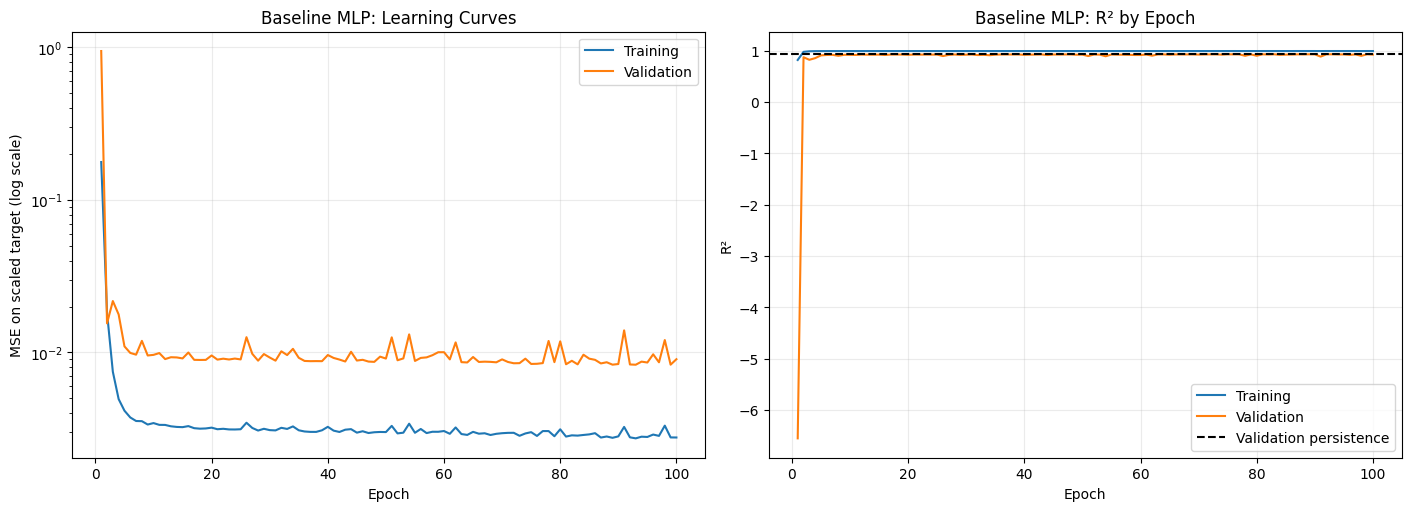

,model,split,MAE,RMSE,R2
0,Persistence,train,0.790716,1.135872,0.997240
1,Persistence,validation,1.497729,1.966823,0.933962
2,MLP (epoch 100),train,0.807170,1.137929,0.997230
3,MLP (epoch 100),validation,1.607750,2.054546,0.927940


In [21]:
fig, axes = plt.subplots(
    1, 2, figsize=(14, 5), constrained_layout=True
)

axes[0].plot(
    history["epoch"], history["train_loss"], label="Training"
)
axes[0].plot(
    history["epoch"], history["validation_loss"], label="Validation"
)
axes[0].set_yscale("log")
axes[0].set_title("Baseline MLP: Learning Curves")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE on scaled target (log scale)")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(
    history["epoch"], history["train_R2"], label="Training"
)
axes[1].plot(
    history["epoch"], history["validation_R2"], label="Validation"
)
axes[1].axhline(
    persistence_results.loc["validation", "R2"],
    color="black",
    linestyle="--",
    label="Validation persistence",
)
axes[1].set_title("Baseline MLP: R² by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("R²")
axes[1].grid(alpha=0.25)
axes[1].legend()

fig.savefig(
    PLOT_DIR / "aapl_baseline_learning_curves.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

final_epoch = history.iloc[-1]

comparison = persistence_results.reset_index()
comparison.insert(0, "model", "Persistence")

mlp_results = pd.DataFrame([
    {
        "model": "MLP (epoch 100)",
        "split": split,
        **{
            metric: final_epoch[f"{prefix}_{metric}"]
            for metric in ["MAE", "RMSE", "R2"]
        },
    }
    for split, prefix in [
        ("train", "train"),
        ("validation", "validation"),
    ]
])

comparison = pd.concat(
    [comparison, mlp_results], ignore_index=True
)

display(comparison.round(6))

comparison.to_csv(
    RESULTS_DIR / "aapl_baseline_comparison.csv",
    index=False,
)

In [22]:
import json

baseline_config = {
    "symbol": SYMBOL,
    "features": FEATURES,
    "target": TARGET,
    "seed": SEED,
    "architecture": {
        "input_dim": len(FEATURES),
        "hidden_layers": [32, 16],
        "activation": "ReLU",
        "output_dim": 1,
        "trainable_parameters": sum(
            p.numel() for p in model.parameters() if p.requires_grad
        ),
    },
    "training": {
        "optimizer": "Adam",
        "learning_rate": LEARNING_RATE,
        "batch_size": BATCH_SIZE,
        "epochs": EPOCHS,
        "loss": "MSE on standardized target",
        "shuffle_training_batches": True,
        "early_stopping": False,
        "weight_decay": 0.0,
        "selection": "Fixed final epoch; no checkpoint selection",
        "device": str(DEVICE),
    },
    "preprocessing": {
        "fit_partition": "train",
        "input_mean": x_scaler.mean_.tolist(),
        "input_scale": x_scaler.scale_.tolist(),
        "target_mean": y_scaler.mean_.tolist(),
        "target_scale": y_scaler.scale_.tolist(),
    },
    "test_evaluated": False,
}

model.eval()
with torch.no_grad():
    saved_val_predictions = y_scaler.inverse_transform(
        model(X_val_tensor.to(DEVICE)).cpu().numpy()
    ).ravel()

np.testing.assert_allclose(
    regression_metrics(y_val_raw.ravel(), saved_val_predictions)["RMSE"],
    comparison.loc[
        (comparison["model"] == "MLP (epoch 100)")
        & (comparison["split"] == "validation"),
        "RMSE",
    ].iloc[0],
    rtol=1e-5,
)

validation_predictions = validation[
    ["date", "target_date", "close", TARGET]
].copy()
validation_predictions["persistence_prediction"] = validation["close"]
validation_predictions["mlp_prediction"] = saved_val_predictions

config_path = RESULTS_DIR / "aapl_baseline_config.json"
config_path.write_text(
    json.dumps(baseline_config, indent=2),
    encoding="utf-8",
)

validation_predictions.to_csv(
    RESULTS_DIR / "aapl_baseline_validation_predictions.csv",
    index=False,
    date_format="%Y-%m-%d",
)

print("PASS: saved predictions match the reported validation RMSE.")
print("Saved configuration:", config_path)
print("Saved validation predictions:", len(validation_predictions))
print("Test set remains unevaluated.")

PASS: saved predictions match the reported validation RMSE.
Saved configuration: /kaggle/working/results/aapl_baseline_config.json
Saved validation predictions: 251
Test set remains unevaluated.


### Baseline regression results

The baseline MLP uses five inputs, two ReLU hidden layers with 32 and
16 neurons, and one linear output (737 trainable parameters).
It was trained with Adam, a learning rate of 0.001, batch size 32,
and a fixed budget of 100 epochs.

Input and target standardization were fitted on training data only.
Metrics were calculated in original price units after inverse-transforming
predictions. The reported model is the final-epoch model; no checkpoint
selection or early stopping was used.

| Model | Partition | MAE (USD) | RMSE (USD) | R² |
|---|---|---:|---:|---:|
| Persistence | Training | 0.790716 | 1.135872 | 0.997240 |
| Persistence | Validation | 1.497729 | 1.966823 | 0.933962 |
| MLP, epoch 100 | Training | 0.807170 | 1.137929 | 0.997230 |
| MLP, epoch 100 | Validation | 1.607750 | 2.054546 | 0.927940 |

The MLP learns rapidly during the initial epochs, after which validation
loss largely plateaus with occasional spikes. The curves do not show
a sustained increase in validation loss.

Persistence outperforms the MLP on both partitions. On validation,
the MLP's MAE is approximately 7.3% higher and its RMSE is 4.5% higher.
High R² alone therefore does not demonstrate improvement over a simple
forecasting baseline.

Validation prices have higher average levels than training prices,
while validation volume is lower on average. This distribution shift
may contribute to the generalization gap, but these results do not
establish its cause.

The test set remains unevaluated. Hyperparameter tuning and controlled
regularization comparisons will follow in later issues.

## 7. GridSearchCV with skorch and TimeSeriesSplit

Search 16 configurations with fold-specific input/target scaling, compare the selected model on 2015 validation data, and record a fixed reporting rerun. The 2016 test set remains reserved.


In [24]:
from sklearn.model_selection import TimeSeriesSplit

X_search_raw = train[FEATURES].to_numpy(dtype=np.float32)
y_search_raw = train[[TARGET]].to_numpy(dtype=np.float32)

time_cv = TimeSeriesSplit(
    n_splits=3,
    test_size=200,
    gap=1,
)

cv_splits = list(time_cv.split(X_search_raw))
fold_rows = []

for fold, (fit_indices, score_indices) in enumerate(cv_splits, start=1):
    fit_part = train.iloc[fit_indices]
    score_part = train.iloc[score_indices]

    assert set(fit_indices).isdisjoint(score_indices)
    assert fit_part["target_date"].max() < score_part["date"].min()

    fold_rows.append({
        "fold": fold,
        "fit_samples": len(fit_part),
        "score_samples": len(score_part),
        "fit_first_date": fit_part["date"].min(),
        "fit_last_input_date": fit_part["date"].max(),
        "fit_last_target_date": fit_part["target_date"].max(),
        "score_first_input_date": score_part["date"].min(),
        "score_last_target_date": score_part["target_date"].max(),
    })

fold_summary = pd.DataFrame(fold_rows).set_index("fold")

display(fold_summary)

fold_summary.to_csv(
    RESULTS_DIR / "aapl_gridsearch_folds.csv",
    date_format="%Y-%m-%d",
)

print("Search input shape:", X_search_raw.shape)
print("Search target shape:", y_search_raw.shape)
print("PASS: all CV target boundaries are separated.")
print("2015 validation and 2016 test data are excluded from the search.")

,fit_samples,score_samples,fit_first_date,fit_last_input_date,fit_last_target_date,score_first_input_date,score_last_target_date
fold,,,,,,,
1,656,200,2010-01-04,2012-08-08,2012-08-09,2012-08-10,2013-05-31
2,856,200,2010-01-04,2013-05-29,2013-05-30,2013-05-31,2014-03-18
3,1056,200,2010-01-04,2014-03-14,2014-03-17,2014-03-18,2014-12-31


Search input shape: (1257, 5)
Search target shape: (1257, 1)
PASS: all CV target boundaries are separated.
2015 validation and 2016 test data are excluded from the search.


In [27]:
from sklearn.compose import TransformedTargetRegressor
from sklearn.model_selection import ParameterGrid
from sklearn.pipeline import Pipeline
from skorch import NeuralNetRegressor


class TunableMLP(nn.Module):
    def __init__(self, input_dim=5, hidden_sizes=(32, 16)):
        super().__init__()

        layers = []
        previous_size = input_dim

        for hidden_size in hidden_sizes:
            layers.extend([
                nn.Linear(previous_size, hidden_size),
                nn.ReLU(),
            ])
            previous_size = hidden_size

        layers.append(nn.Linear(previous_size, 1))
        self.network = nn.Sequential(*layers)

    def forward(self, x):
        return self.network(x)


class SeededNeuralNetRegressor(NeuralNetRegressor):
    def initialize(self):
        random.seed(SEED)
        np.random.seed(SEED)
        torch.manual_seed(SEED)

        if torch.cuda.is_available():
            torch.cuda.manual_seed_all(SEED)

        return super().initialize()

    def fit(self, X, y, **fit_params):
        y = np.asarray(y, dtype=np.float32).reshape(-1, 1)
        return super().fit(X, y, **fit_params)

    def get_loss(self, y_pred, y_true, X=None, training=False):
        if y_pred.shape != y_true.shape:
            raise ValueError(
                f"Prediction shape {y_pred.shape} "
                f"does not match target shape {y_true.shape}"
            )

        return super().get_loss(
            y_pred, y_true, X=X, training=training
        )


search_net = SeededNeuralNetRegressor(
    module=TunableMLP,
    module__input_dim=len(FEATURES),
    criterion=nn.MSELoss,
    optimizer=torch.optim.Adam,
    batch_size=32,
    train_split=False,
    iterator_train__shuffle=True,
    iterator_train__num_workers=0,
    device=DEVICE,
    verbose=0,
)

search_estimator = TransformedTargetRegressor(
    regressor=Pipeline([
        ("scale", StandardScaler()),
        ("net", search_net),
    ]),
    transformer=StandardScaler(),
)

param_grid = {
    "regressor__net__lr": [0.001, 0.005],
    "regressor__net__optimizer": [
        torch.optim.Adam,
        torch.optim.RMSprop,
    ],
    "regressor__net__max_epochs": [50, 100],
    "regressor__net__module__hidden_sizes": [
        (32, 16),
        (64, 32, 16),
    ],
}

candidates = list(ParameterGrid(param_grid))

print("Candidate configurations:", len(candidates))
print("CV folds:", len(cv_splits))
print("CV training runs:", len(candidates) * len(cv_splits))
print("Final refits: 1")
print("Input scaling: fitted separately within each fold.")
print("Target scaling: fitted separately within each fold.")
print("Scoring: negative MSE in original USD² units.")
print("Early stopping: disabled; each fit uses its fixed epoch budget.")

Candidate configurations: 16
CV folds: 3
CV training runs: 48
Final refits: 1
Input scaling: fitted separately within each fold.
Target scaling: fitted separately within each fold.
Scoring: negative MSE in original USD² units.
Early stopping: disabled; each fit uses its fixed epoch budget.


In [28]:
from sklearn.base import clone
import warnings

shape_check = clone(search_estimator).set_params(
    regressor__net__max_epochs=2,
    regressor__net__lr=0.001,
)

fit_indices, score_indices = cv_splits[0]

with warnings.catch_warnings():
    warnings.filterwarnings(
        "error",
        message="Using a target size.*",
        category=UserWarning,
    )

    shape_check.fit(
        X_search_raw[fit_indices],
        y_search_raw[fit_indices],
    )

check_predictions = shape_check.predict(
    X_search_raw[score_indices[:8]]
)

assert check_predictions.shape == (8, 1)
assert np.isfinite(check_predictions).all()

print("PASS: wrapper training completed without target broadcasting.")
print("Prediction shape:", check_predictions.shape)

PASS: wrapper training completed without target broadcasting.
Prediction shape: (8, 1)


In [29]:
import time

grid_search = GridSearchCV(
    estimator=search_estimator,
    param_grid=param_grid,
    scoring="neg_mean_squared_error",
    cv=cv_splits,
    refit=True,
    n_jobs=1,
    error_score="raise",
    return_train_score=True,
    verbose=2,
)

search_start = time.perf_counter()
grid_search.fit(X_search_raw, y_search_raw)
search_seconds = time.perf_counter() - search_start

cv_results = pd.DataFrame(grid_search.cv_results_)

assert len(cv_results) == len(candidates)
assert np.isfinite(cv_results["mean_test_score"]).all()

cv_results.to_csv(
    RESULTS_DIR / "aapl_gridsearch_cv_results.csv",
    index=False,
)

search_ranking = pd.DataFrame({
    "rank": cv_results["rank_test_score"],
    "learning_rate": cv_results["param_regressor__net__lr"].astype(float),
    "optimizer": [
        optimizer.__name__
        for optimizer in cv_results["param_regressor__net__optimizer"]
    ],
    "epochs": cv_results["param_regressor__net__max_epochs"].astype(int),
    "hidden_layers": cv_results[
        "param_regressor__net__module__hidden_sizes"
    ].map(str),
    "mean_cv_mse": -cv_results["mean_test_score"],
    "std_cv_mse": cv_results["std_test_score"],
    "mean_fit_seconds": cv_results["mean_fit_time"],
}).sort_values(["rank", "mean_fit_seconds"]).reset_index(drop=True)

search_ranking.to_csv(
    RESULTS_DIR / "aapl_gridsearch_ranking.csv",
    index=False,
)

print(f"\nSearch completed in {search_seconds / 60:.2f} minutes.")
print("Best parameters:", grid_search.best_params_)
print(f"Best mean CV MSE: {-grid_search.best_score_:.6f} USD²")
display(search_ranking.round(6))

Fitting 3 folds for each of 16 candidates, totalling 48 fits
[CV] END regressor__net__lr=0.001, regressor__net__max_epochs=50, regressor__net__module__hidden_sizes=(32, 16), regressor__net__optimizer=<class 'torch.optim.adam.Adam'>; total time=   2.2s
[CV] END regressor__net__lr=0.001, regressor__net__max_epochs=50, regressor__net__module__hidden_sizes=(32, 16), regressor__net__optimizer=<class 'torch.optim.adam.Adam'>; total time=   2.7s
[CV] END regressor__net__lr=0.001, regressor__net__max_epochs=50, regressor__net__module__hidden_sizes=(32, 16), regressor__net__optimizer=<class 'torch.optim.adam.Adam'>; total time=   3.1s
[CV] END regressor__net__lr=0.001, regressor__net__max_epochs=50, regressor__net__module__hidden_sizes=(32, 16), regressor__net__optimizer=<class 'torch.optim.rmsprop.RMSprop'>; total time=   1.9s
[CV] END regressor__net__lr=0.001, regressor__net__max_epochs=50, regressor__net__module__hidden_sizes=(32, 16), regressor__net__optimizer=<class 'torch.optim.rmsprop.RM

,rank,learning_rate,optimizer,epochs,hidden_layers,mean_cv_mse,std_cv_mse,mean_fit_seconds
0,1,0.001,Adam,50,"(32, 16)",2.163347,0.554901,2.673751
1,2,0.005,Adam,100,"(32, 16)",2.203387,0.781465,5.112953
2,3,0.001,Adam,50,"(64, 32, 16)",2.222756,0.959608,2.982923
3,4,0.001,RMSprop,100,"(32, 16)",2.223523,0.713756,5.169168
4,5,0.005,Adam,50,"(64, 32, 16)",2.230340,0.922613,2.788274
5,6,0.005,Adam,100,"(64, 32, 16)",2.345863,0.810750,5.548600
6,7,0.001,Adam,100,"(64, 32, 16)",2.458575,0.877827,5.657468
7,8,0.001,Adam,100,"(32, 16)",2.491801,0.886646,5.405269
8,9,0.001,RMSprop,100,"(64, 32, 16)",2.646958,0.990329,5.396817
9,10,0.005,Adam,50,"(32, 16)",2.818438,1.190018,2.552273


In [30]:
best_estimator = grid_search.best_estimator_

fitted_input_scaler = best_estimator.regressor_.named_steps["scale"]
fitted_target_scaler = best_estimator.transformer_

assert int(fitted_input_scaler.n_samples_seen_) == len(train)
assert int(fitted_target_scaler.n_samples_seen_) == len(train)

tuned_train_predictions = best_estimator.predict(
    train[FEATURES].to_numpy(dtype=np.float32)
).ravel()

tuned_val_predictions = best_estimator.predict(
    validation[FEATURES].to_numpy(dtype=np.float32)
).ravel()

assert np.isfinite(tuned_train_predictions).all()
assert np.isfinite(tuned_val_predictions).all()

tuned_rows = pd.DataFrame([
    {
        "model": "CV-selected MLP",
        "split": split,
        **regression_metrics(
            part[TARGET].to_numpy(),
            predictions,
        ),
    }
    for split, part, predictions in [
        ("train", train, tuned_train_predictions),
        ("validation", validation, tuned_val_predictions),
    ]
])

tuning_comparison = pd.concat(
    [
        comparison.loc[
            comparison["model"].isin(["Persistence", "MLP (epoch 100)"])
        ],
        tuned_rows,
    ],
    ignore_index=True,
)

display(tuning_comparison.round(6))

tuning_comparison.to_csv(
    RESULTS_DIR / "aapl_tuning_comparison.csv",
    index=False,
)

tuned_prediction_table = validation[
    ["date", "target_date", "close", TARGET]
].copy()
tuned_prediction_table["tuned_mlp_prediction"] = tuned_val_predictions

tuned_prediction_table.to_csv(
    RESULTS_DIR / "aapl_tuned_validation_predictions.csv",
    index=False,
    date_format="%Y-%m-%d",
)

print("PASS: final refit scalers used training data only.")
print("Predictions are in original price units.")
print("Test set remains unevaluated.")

,model,split,MAE,RMSE,R2
0,Persistence,train,0.790716,1.135872,0.997240
1,Persistence,validation,1.497729,1.966823,0.933962
2,MLP (epoch 100),train,0.807170,1.137929,0.997230
3,MLP (epoch 100),validation,1.607750,2.054546,0.927940
4,CV-selected MLP,train,0.842932,1.182330,0.997010
5,CV-selected MLP,validation,1.615260,2.063188,0.927332


PASS: final refit scalers used training data only.
Predictions are in original price units.
Test set remains unevaluated.


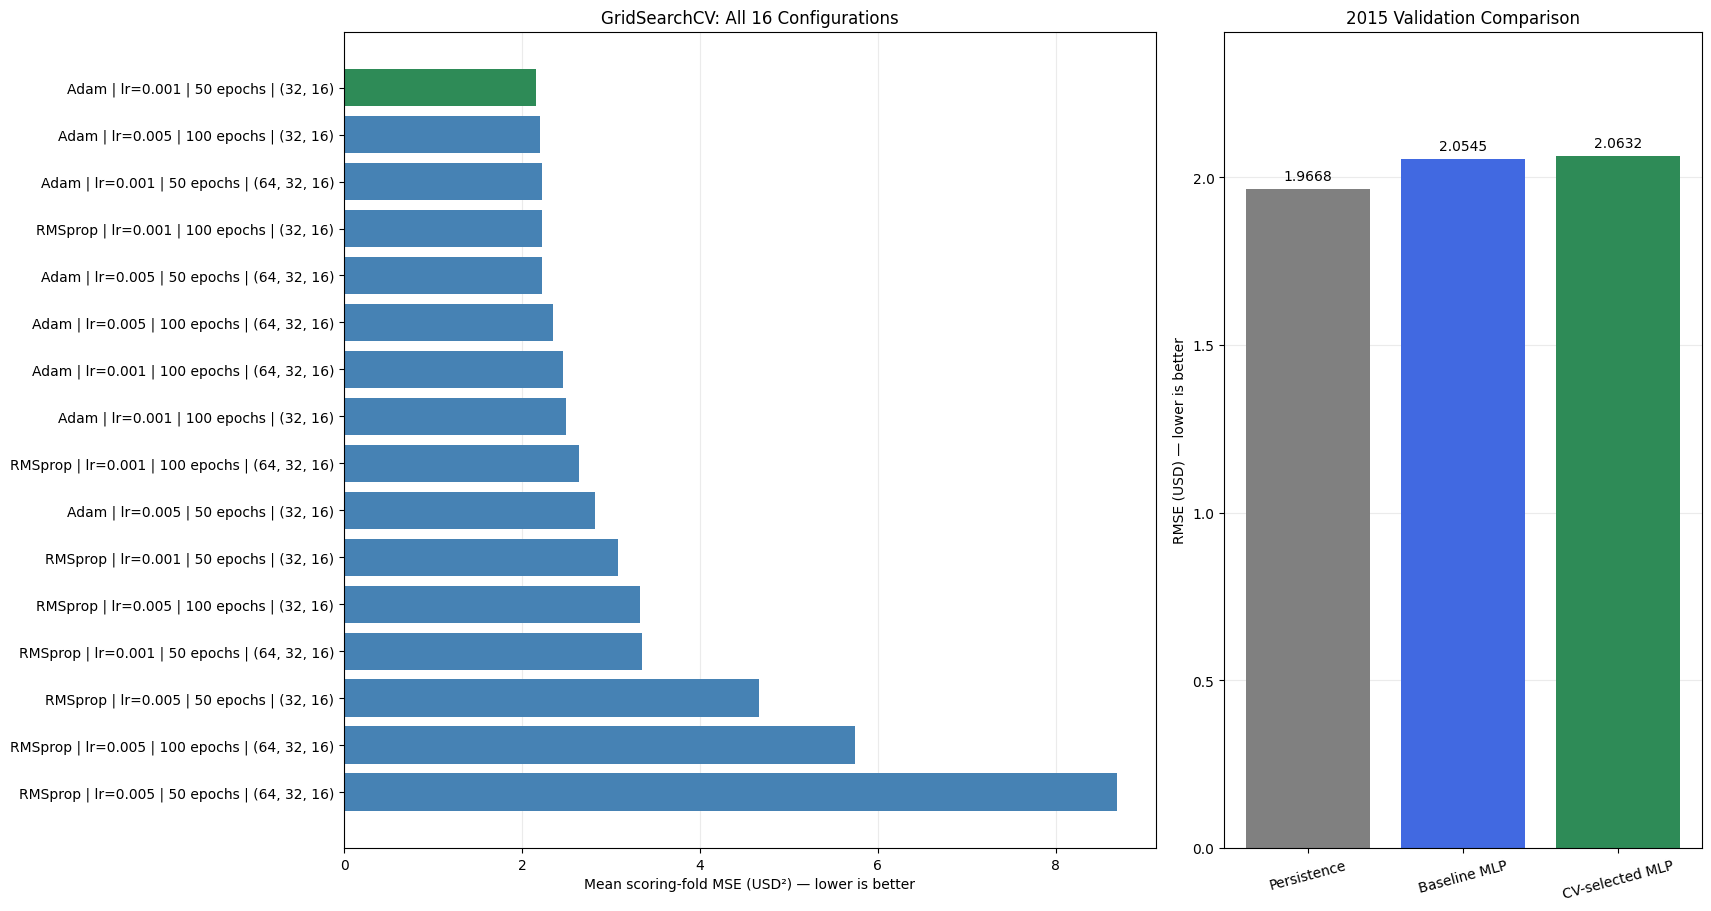

In [31]:
ranking_plot = search_ranking.sort_values("rank").copy()

candidate_labels = [
    f"{row.optimizer} | lr={row.learning_rate:g} | "
    f"{row.epochs} epochs | {row.hidden_layers}"
    for row in ranking_plot.itertuples()
]

validation_plot = (
    tuning_comparison.loc[tuning_comparison["split"].eq("validation")]
    .set_index("model")
    .loc[["Persistence", "MLP (epoch 100)", "CV-selected MLP"]]
)

fig, axes = plt.subplots(
    1, 2,
    figsize=(17, 9),
    gridspec_kw={"width_ratios": [1.7, 1]},
    constrained_layout=True,
)

bar_colors = [
    "seagreen" if rank == 1 else "steelblue"
    for rank in ranking_plot["rank"]
]

axes[0].barh(
    candidate_labels,
    ranking_plot["mean_cv_mse"],
    color=bar_colors,
)
axes[0].invert_yaxis()
axes[0].set_title("GridSearchCV: All 16 Configurations")
axes[0].set_xlabel("Mean scoring-fold MSE (USD²) — lower is better")
axes[0].grid(axis="x", alpha=0.25)
axes[0].set_axisbelow(True)

bars = axes[1].bar(
    ["Persistence", "Baseline MLP", "CV-selected MLP"],
    validation_plot["RMSE"],
    color=["gray", "royalblue", "seagreen"],
)

axes[1].bar_label(bars, fmt="%.4f", padding=4)
axes[1].set_ylim(0, validation_plot["RMSE"].max() * 1.18)
axes[1].set_title("2015 Validation Comparison")
axes[1].set_ylabel("RMSE (USD) — lower is better")
axes[1].tick_params(axis="x", labelrotation=15)
axes[1].grid(axis="y", alpha=0.25)
axes[1].set_axisbelow(True)

fig.savefig(
    PLOT_DIR / "aapl_gridsearch_and_validation_comparison.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

In [32]:
best_params = grid_search.best_params_
best_net = best_estimator.regressor_.named_steps["net"]

search_config = {
    "symbol": SYMBOL,
    "features": FEATURES,
    "target": TARGET,
    "seed": SEED,
    "search_partition": "2010–2014 training data only",
    "selection_metric": "Mean CV MSE in original USD² units",
    "cv": {
        "method": "TimeSeriesSplit",
        "n_splits": 3,
        "test_size": 200,
        "gap": 1,
    },
    "search_space": {
        "learning_rate": [0.001, 0.005],
        "optimizer": ["Adam", "RMSprop"],
        "epochs": [50, 100],
        "hidden_layers": [[32, 16], [64, 32, 16]],
    },
    "candidate_count": len(candidates),
    "cv_fit_count": len(candidates) * len(cv_splits),
    "refit_count": 1,
    "elapsed_seconds": float(search_seconds),
    "best_parameters": {
        "learning_rate": float(best_params["regressor__net__lr"]),
        "optimizer": best_params["regressor__net__optimizer"].__name__,
        "epochs": int(best_params["regressor__net__max_epochs"]),
        "hidden_layers": list(
            best_params["regressor__net__module__hidden_sizes"]
        ),
        "batch_size": 32,
    },
    "best_mean_cv_mse": float(-grid_search.best_score_),
    "best_fold_mse": [
        float(-grid_search.cv_results_[f"split{i}_test_score"][
            grid_search.best_index_
        ])
        for i in range(len(cv_splits))
    ],
    "preprocessing": {
        "cv_scaling": "Input and target scalers fitted within each fold",
        "refit_samples": int(fitted_input_scaler.n_samples_seen_),
        "input_mean": fitted_input_scaler.mean_.tolist(),
        "input_scale": fitted_input_scaler.scale_.tolist(),
        "target_mean": fitted_target_scaler.mean_.tolist(),
        "target_scale": fitted_target_scaler.scale_.tolist(),
    },
    "target_shape": "Restored to (n_samples, 1) before skorch fitting",
    "early_stopping": False,
    "validation_used_for_search": False,
    "test_evaluated": False,
}

assert len(best_net.history) == search_config["best_parameters"]["epochs"]

config_path = RESULTS_DIR / "aapl_gridsearch_config.json"
config_path.write_text(
    json.dumps(search_config, indent=2),
    encoding="utf-8",
)

print("Best configuration:", search_config["best_parameters"])
print("Selected configuration's fold MSEs:", search_config["best_fold_mse"])
print("Final refit epochs:", len(best_net.history))
print("Saved:", config_path)

Best configuration: {'learning_rate': 0.001, 'optimizer': 'Adam', 'epochs': 50, 'hidden_layers': [32, 16], 'batch_size': 32}
Selected configuration's fold MSEs: [2.7824785709381104, 1.4361939430236816, 2.2713675498962402]
Final refit epochs: 50
Saved: /kaggle/working/results/aapl_gridsearch_config.json


In [33]:
from sklearn.base import clone
from skorch.callbacks import Callback

curve_X_train = fitted_input_scaler.transform(
    train[FEATURES].to_numpy(dtype=np.float32)
).astype(np.float32)

curve_X_val = fitted_input_scaler.transform(
    validation[FEATURES].to_numpy(dtype=np.float32)
).astype(np.float32)

curve_y_train = fitted_target_scaler.transform(
    train[[TARGET]].to_numpy(dtype=np.float32)
).astype(np.float32)

curve_y_val = fitted_target_scaler.transform(
    validation[[TARGET]].to_numpy(dtype=np.float32)
).astype(np.float32)


class LearningCurveRecorder(Callback):
    def initialize(self):
        self.rows = []
        return self

    def on_epoch_end(self, net, **kwargs):
        row = {"epoch": len(net.history)}
        was_training = net.module_.training
        net.module_.eval()

        with torch.no_grad():
            for name, X, y, actual in [
                ("train", curve_X_train, curve_y_train, train[TARGET]),
                ("validation", curve_X_val, curve_y_val, validation[TARGET]),
            ]:
                prediction = net.module_(
                    torch.as_tensor(X, device=net.device)
                ).cpu().numpy()

                prediction_usd = fitted_target_scaler.inverse_transform(
                    prediction
                ).ravel()

                row[f"{name}_loss"] = float(np.mean((prediction - y) ** 2))
                row[f"{name}_R2"] = r2_score(
                    actual.to_numpy(), prediction_usd
                )

        net.module_.train(was_training)
        self.rows.append(row)


curve_net = clone(best_net)
curve_net.set_params(
    callbacks=[("learning_curves", LearningCurveRecorder())]
)
curve_net.fit(curve_X_train, curve_y_train)

curve_recorder = dict(curve_net.callbacks_)["learning_curves"]
tuned_history = pd.DataFrame(curve_recorder.rows)

assert len(tuned_history) == search_config["best_parameters"]["epochs"]
assert np.isfinite(tuned_history.to_numpy()).all()

reporting_predictions = fitted_target_scaler.inverse_transform(
    curve_net.predict(curve_X_val)
).ravel()

reporting_metrics = regression_metrics(
    validation[TARGET].to_numpy(),
    reporting_predictions,
)

tuned_history.to_csv(
    RESULTS_DIR / "aapl_tuned_reporting_history.csv",
    index=False,
)

print("Reporting-run epochs:", len(tuned_history))
print("Reporting-run validation metrics:", reporting_metrics)
print(
    "Maximum prediction difference from original selected model:",
    np.max(np.abs(reporting_predictions - tuned_val_predictions)),
)
display(tuned_history.tail())

Reporting-run epochs: 50
Reporting-run validation metrics: {'MAE': 1.6152595272173025, 'RMSE': np.float64(2.06318813021424), 'R2': 0.9273321804238869}
Maximum prediction difference from original selected model: 0.0


,epoch,train_loss,train_R2,validation_loss,validation_R2
45,46,0.003137,0.996863,0.009675,0.922782
46,47,0.003081,0.996919,0.009441,0.924650
47,48,0.003028,0.996972,0.009399,0.924985
48,49,0.003019,0.996981,0.008606,0.931310
49,50,0.002990,0.997010,0.009105,0.927332


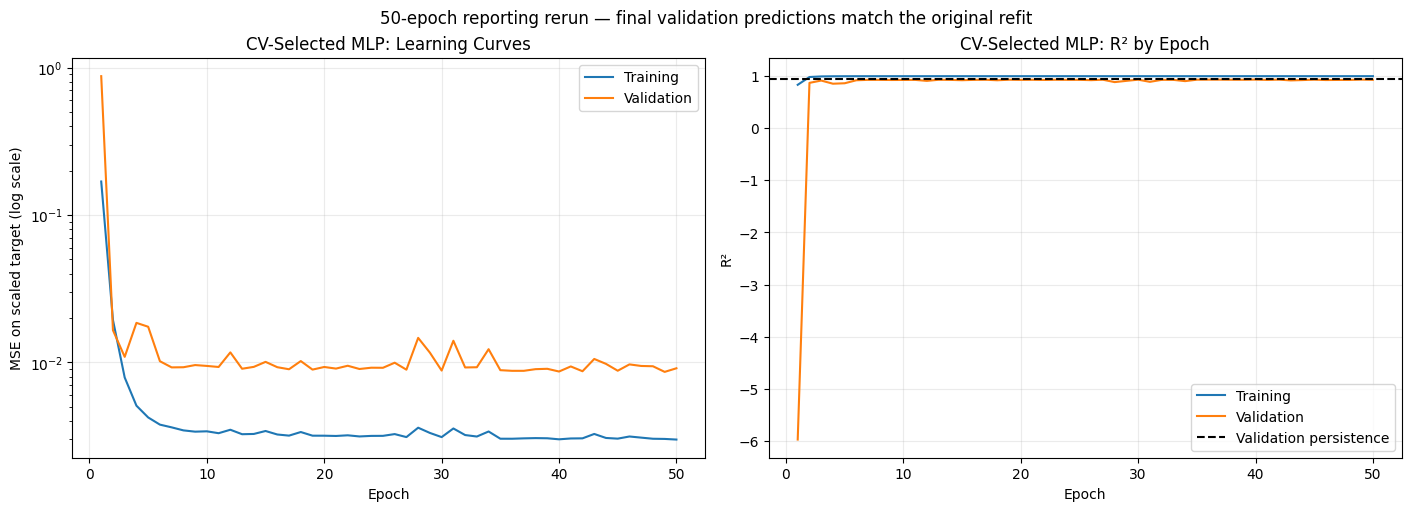

In [34]:
fig, axes = plt.subplots(
    1, 2, figsize=(14, 5), constrained_layout=True
)

axes[0].plot(
    tuned_history["epoch"],
    tuned_history["train_loss"],
    label="Training",
)
axes[0].plot(
    tuned_history["epoch"],
    tuned_history["validation_loss"],
    label="Validation",
)
axes[0].set_yscale("log")
axes[0].set_title("CV-Selected MLP: Learning Curves")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("MSE on scaled target (log scale)")
axes[0].grid(alpha=0.25)
axes[0].legend()

axes[1].plot(
    tuned_history["epoch"],
    tuned_history["train_R2"],
    label="Training",
)
axes[1].plot(
    tuned_history["epoch"],
    tuned_history["validation_R2"],
    label="Validation",
)
axes[1].axhline(
    persistence_results.loc["validation", "R2"],
    color="black",
    linestyle="--",
    label="Validation persistence",
)
axes[1].set_title("CV-Selected MLP: R² by Epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("R²")
axes[1].grid(alpha=0.25)
axes[1].legend()

fig.suptitle(
    "50-epoch reporting rerun — final validation predictions match "
    "the original refit",
    fontsize=12,
)

fig.savefig(
    PLOT_DIR / "aapl_tuned_learning_curves.png",
    dpi=160,
    bbox_inches="tight",
)
plt.show()

### Hyperparameter tuning results

GridSearchCV evaluated 16 configurations using three expanding
chronological folds within the 2010–2014 training partition.
Each scoring fold contained 200 samples, with a one-row gap to
prevent training targets from crossing the scoring boundary.

Input and target scalers were fitted separately within each fold.
Selection used mean scoring-fold MSE in original USD² units.
Neither 2015 validation data nor 2016 test data was used in the search.

The search covered:
- Learning rate: 0.001 and 0.005
- Optimizer: Adam and RMSprop
- Epochs: 50 and 100
- Hidden layers: (32, 16) and (64, 32, 16)

### Selected configuration

Adam, learning rate 0.001, hidden layers (32, 16), batch size 32,
and 50 epochs.

The selected configuration achieved mean CV MSE of 2.163347 USD².
Its three fold MSEs were 2.782479, 1.436194, and 2.271368 USD².
GridSearchCV then refitted it on all 1,257 training samples.

| Model | Validation MAE (USD) | Validation RMSE (USD) | Validation R² |
|---|---:|---:|---:|
| Persistence | 1.497729 | 1.966823 | 0.933962 |
| Original MLP, 100 epochs | 1.607750 | 2.054546 | 0.927940 |
| CV-selected MLP, 50 epochs | 1.615260 | 2.063188 | 0.927332 |

The CV-selected configuration did not improve on the original MLP
on 2015 validation data. Persistence remained the strongest benchmark.
Selection on earlier chronological folds does not guarantee improvement
in a later period. These results concern the tested grid and seed,
not every possible MLP configuration.

### Implementation verification

An initial target-shape mismatch was detected and corrected before
the reported search. The wrapper restores targets to (n_samples, 1),
and the loss rejects mismatched prediction/target shapes.
Results from the incorrect run were discarded.

The corrected wrapper passed a short training check before the full
search was rerun. The test set remains unevaluated.

The learning curves come from a separate 50-epoch reporting run using
the fixed CV-selected configuration and training-fitted scalers.
Its final validation predictions exactly matched the original
GridSearchCV refit (maximum absolute difference: 0.0).
Validation metrics were recorded for interpretation only; they were
not used for early stopping or checkpoint selection.

## 8. Controlled regularization comparisons

TODO: implement and document this section.


## 9. Frozen-model train/test curves and final metrics

TODO: implement and document this section.


## 10. Interpretation and exported results

TODO: implement and document this section.
